In [1]:

# Zajęcie 1 – Nauka o danych
# Wariant 4: United States Healthcare Spending by Race and Ethnicity 2002–2016

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import zipfile
import io

print("Biblioteki zostały zaimportowane poprawnie.")
print("Wersja pandas:", pd.__version__)


Biblioteki zostały zaimportowane poprawnie.
Wersja pandas: 2.2.3


In [2]:

from google.colab import files

uploaded = files.upload()


Saving IHME_USA_HEALTH_SPENDING_RACE_ETHNICITY_2002_2016_DATA.zip to IHME_USA_HEALTH_SPENDING_RACE_ETHNICITY_2002_2016_DATA.zip


In [3]:

# Odczyt pliku CSV bezpośrednio z archiwum ZIP

zip_filename = next(iter(uploaded))

with zipfile.ZipFile(io.BytesIO(uploaded[zip_filename])) as archive:
    csv_files = [
        name for name in archive.namelist()
        if name.lower().endswith(".csv")
    ]

    print("Pliki CSV w archiwum:")
    for name in csv_files:
        print(name)

    data_filename = csv_files[0]

    with archive.open(data_filename) as file:
        df = pd.read_csv(file, low_memory=False)

print("\nDane zostały wczytane.")
print("Liczba wierszy i kolumn:", df.shape)


Pliki CSV w archiwum:
IHME_USA_HEALTH_SPENDING_RACE_ETHNICITY_2002_2016_DATA_Y2021M08D17.CSV

Dane zostały wczytane.
Liczba wierszy i kolumn: (598500, 13)


In [4]:

display(df.head(10))


,year,age_group_id,age_group_name,sex_id,sex,race_ethnicity,acause,acause_name,type_care,spending_unit,val,upper,lower
0,2002,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Ambulatory Care,Spending in 2016 USD (millions),104.39,146.97,67.56
1,2002,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Dental Care,Spending in 2016 USD (millions),3.04,7.06,1.12
2,2002,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Emergency Department Care,Spending in 2016 USD (millions),24.87,37.16,12.40
3,2002,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Inpatient Care,Spending in 2016 USD (millions),24.94,46.69,5.03
4,2002,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Nursing Facility Care,Spending in 2016 USD (millions),2.02,15.82,0.05
5,2002,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Prescribed Pharmaceuticals,Spending in 2016 USD (millions),20.95,32.15,8.14
6,2002,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Total,Spending in 2016 USD (millions),180.21,237.08,135.62
7,2002,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",cvd,Cardiovascular diseases,Ambulatory Care,Spending in 2016 USD (millions),1.66,3.95,0.25
8,2002,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",cvd,Cardiovascular diseases,Emergency Department Care,Spending in 2016 USD (millions),0.21,0.58,0.03
9,2002,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",cvd,Cardiovascular diseases,Inpatient Care,Spending in 2016 USD (millions),1.59,5.85,0.20


In [5]:

# Wyświetlenie ostatnich 10 wierszy
display(df.tail(10))

# Informacje o ramce danych
df.info()

# Liczba wierszy i kolumn
print("Liczba wierszy:", df.shape[0])
print("Liczba kolumn:", df.shape[1])

# Nazwy kolumn
print("\nNazwy kolumn:")
print(df.columns.tolist())


,year,age_group_id,age_group_name,sex_id,sex,race_ethnicity,acause,acause_name,type_care,spending_unit,val,upper,lower
598490,2016,22,All Ages,1,Male,White (non-Hispanic),resp_copd,COPD,Inpatient Care,Spending per capita in 2016 USD,26.0,34.0,16.0
598491,2016,22,All Ages,1,Male,White (non-Hispanic),resp_copd,COPD,Nursing Facility Care,Spending per capita in 2016 USD,13.0,17.0,10.0
598492,2016,22,All Ages,1,Male,White (non-Hispanic),resp_copd,COPD,Prescribed Pharmaceuticals,Spending per capita in 2016 USD,36.0,46.0,27.0
598493,2016,22,All Ages,1,Male,White (non-Hispanic),resp_copd,COPD,Total,Spending per capita in 2016 USD,98.0,113.0,81.0
598494,2016,22,All Ages,1,Male,White (non-Hispanic),rf_hypertension,Hypertension,Ambulatory Care,Spending per capita in 2016 USD,165.0,213.0,134.0
598495,2016,22,All Ages,1,Male,White (non-Hispanic),rf_hypertension,Hypertension,Emergency Department Care,Spending per capita in 2016 USD,9.0,12.0,6.0
598496,2016,22,All Ages,1,Male,White (non-Hispanic),rf_hypertension,Hypertension,Inpatient Care,Spending per capita in 2016 USD,6.0,8.0,3.0
598497,2016,22,All Ages,1,Male,White (non-Hispanic),rf_hypertension,Hypertension,Nursing Facility Care,Spending per capita in 2016 USD,18.0,30.0,8.0
598498,2016,22,All Ages,1,Male,White (non-Hispanic),rf_hypertension,Hypertension,Prescribed Pharmaceuticals,Spending per capita in 2016 USD,31.0,33.0,28.0
598499,2016,22,All Ages,1,Male,White (non-Hispanic),rf_hypertension,Hypertension,Total,Spending per capita in 2016 USD,229.0,276.0,193.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 598500 entries, 0 to 598499
Data columns (total 13 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   year            598500 non-null  int64  
 1   age_group_id    598500 non-null  int64  
 2   age_group_name  598500 non-null  object 
 3   sex_id          598500 non-null  int64  
 4   sex             598500 non-null  object 
 5   race_ethnicity  598500 non-null  object 
 6   acause          598500 non-null  object 
 7   acause_name     598500 non-null  object 
 8   type_care       598500 non-null  object 
 9   spending_unit   598500 non-null  object 
 10  val             598500 non-null  float64
 11  upper           598500 non-null  float64
 12  lower           598500 non-null  float64
dtypes: float64(3), int64(3), object(7)
memory usage: 59.4+ MB
Liczba wierszy: 598500
Liczba kolumn: 13

Nazwy kolumn:
['year', 'age_group_id', 'age_group_name', 'sex_id', 'sex', 'race_ethnicity', 'a

In [6]:

# Statystyki opisowe kolumn liczbowych
display(df.describe())

# Statystyki opisowe wszystkich kolumn,
# również kategoryzowanych
display(df.describe(include="all"))


,year,age_group_id,sex_id,val,upper,lower
count,598500.000000,598500.000000,598500.000000,5.985000e+05,5.985000e+05,5.985000e+05
mean,2009.000000,21.955789,2.000000,1.236938e+03,1.390616e+03,1.112925e+03
std,4.320497,32.813249,0.816497,1.818914e+04,1.841754e+04,1.799055e+04
min,2002.000000,5.000000,1.000000,0.000000e+00,0.000000e+00,0.000000e+00
25%,2005.000000,9.000000,1.000000,3.090000e+00,7.000000e+00,0.000000e+00
50%,2009.000000,14.000000,2.000000,2.626000e+01,4.500000e+01,9.480000e+00
75%,2013.000000,19.000000,3.000000,1.990000e+02,2.869350e+02,1.210000e+02
max,2016.000000,160.000000,3.000000,2.440175e+06,2.440175e+06,2.440175e+06


,year,age_group_id,age_group_name,sex_id,sex,race_ethnicity,acause,acause_name,type_care,spending_unit,val,upper,lower
count,598500.000000,598500.000000,598500,598500.000000,598500,598500,598500,598500,598500,598500,5.985000e+05,5.985000e+05,5.985000e+05
unique,NaN,NaN,20,NaN,3,7,8,8,7,2,NaN,NaN,NaN
top,NaN,NaN,10 to 14,NaN,Both,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Ambulatory Care,Spending in 2016 USD (millions),NaN,NaN,NaN
freq,NaN,NaN,30870,NaN,199500,85500,88200,88200,97650,299250,NaN,NaN,NaN
mean,2009.000000,21.955789,NaN,2.000000,NaN,NaN,NaN,NaN,NaN,NaN,1.236938e+03,1.390616e+03,1.112925e+03
std,4.320497,32.813249,NaN,0.816497,NaN,NaN,NaN,NaN,NaN,NaN,1.818914e+04,1.841754e+04,1.799055e+04
min,2002.000000,5.000000,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,0.000000e+00,0.000000e+00,0.000000e+00
25%,2005.000000,9.000000,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,3.090000e+00,7.000000e+00,0.000000e+00
50%,2009.000000,14.000000,NaN,2.000000,NaN,NaN,NaN,NaN,NaN,NaN,2.626000e+01,4.500000e+01,9.480000e+00
75%,2013.000000,19.000000,NaN,3.000000,NaN,NaN,NaN,NaN,NaN,NaN,1.990000e+02,2.869350e+02,1.210000e+02


In [7]:

# Liczba brakujących wartości w każdej kolumnie
print("Brakujące wartości:")
display(df.isnull().sum())

# Łączna liczba brakujących wartości
print("Łącznie brakujących wartości:", df.isnull().sum().sum())

# Utworzenie kopii bez wierszy zawierających braki
df_clean = df.dropna().copy()

print("Rozmiar przed usunięciem braków:", df.shape)
print("Rozmiar po usunięciu braków:", df_clean.shape)


Brakujące wartości:


,0
year,0
age_group_id,0
age_group_name,0
sex_id,0
sex,0
race_ethnicity,0
acause,0
acause_name,0
type_care,0
spending_unit,0


Łącznie brakujących wartości: 0
Rozmiar przed usunięciem braków: (598500, 13)
Rozmiar po usunięciu braków: (598500, 13)


In [8]:

# Ramka danych utworzona ze słownika
sample_dict = {
    "Rok": [2002, 2003, 2004],
    "Wydatki_USD": [1200, 1350, 1420],
    "Grupa": ["A", "B", "A"]
}

df_dict = pd.DataFrame(sample_dict)

print("Ramka danych ze słownika:")
display(df_dict)


# Ramka danych utworzona z listy list
sample_list = [
    [2002, 1200, "A"],
    [2003, 1350, "B"],
    [2004, 1420, "A"]
]

df_list = pd.DataFrame(
    sample_list,
    columns=["Rok", "Wydatki_USD", "Grupa"]
)

print("Ramka danych z listy list:")
display(df_list)


# Transponowanie ramki danych
print("Ramka danych po transponowaniu:")
display(df_dict.T)


Ramka danych ze słownika:


,Rok,Wydatki_USD,Grupa
0,2002,1200,A
1,2003,1350,B
2,2004,1420,A


Ramka danych z listy list:


,Rok,Wydatki_USD,Grupa
0,2002,1200,A
1,2003,1350,B
2,2004,1420,A


Ramka danych po transponowaniu:


,0,1,2
Rok,2002,2003,2004
Wydatki_USD,1200,1350,1420
Grupa,A,B,A


In [9]:

# Wybór jednej kolumny
display(df["race_ethnicity"].head(10))

# Wybór kilku kolumn
display(df[["year", "race_ethnicity", "type_care", "val"]].head(10))

# Wybór wierszy według indeksów
display(df.iloc[0:5])

# Wybór określonych wierszy i kolumn według indeksów
display(df.iloc[0:5, 0:4])

# Wybór wierszy i kolumn według nazw
display(df.loc[0:4, ["year", "race_ethnicity", "val"]])


,race_ethnicity
0,"American Indian, Alaska Native (non-Hispanic)"
1,"American Indian, Alaska Native (non-Hispanic)"
2,"American Indian, Alaska Native (non-Hispanic)"
3,"American Indian, Alaska Native (non-Hispanic)"
4,"American Indian, Alaska Native (non-Hispanic)"
5,"American Indian, Alaska Native (non-Hispanic)"
6,"American Indian, Alaska Native (non-Hispanic)"
7,"American Indian, Alaska Native (non-Hispanic)"
8,"American Indian, Alaska Native (non-Hispanic)"
9,"American Indian, Alaska Native (non-Hispanic)"


,year,race_ethnicity,type_care,val
0,2002,"American Indian, Alaska Native (non-Hispanic)",Ambulatory Care,104.39
1,2002,"American Indian, Alaska Native (non-Hispanic)",Dental Care,3.04
2,2002,"American Indian, Alaska Native (non-Hispanic)",Emergency Department Care,24.87
3,2002,"American Indian, Alaska Native (non-Hispanic)",Inpatient Care,24.94
4,2002,"American Indian, Alaska Native (non-Hispanic)",Nursing Facility Care,2.02
5,2002,"American Indian, Alaska Native (non-Hispanic)",Prescribed Pharmaceuticals,20.95
6,2002,"American Indian, Alaska Native (non-Hispanic)",Total,180.21
7,2002,"American Indian, Alaska Native (non-Hispanic)",Ambulatory Care,1.66
8,2002,"American Indian, Alaska Native (non-Hispanic)",Emergency Department Care,0.21
9,2002,"American Indian, Alaska Native (non-Hispanic)",Inpatient Care,1.59


,year,age_group_id,age_group_name,sex_id,sex,race_ethnicity,acause,acause_name,type_care,spending_unit,val,upper,lower
0,2002,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Ambulatory Care,Spending in 2016 USD (millions),104.39,146.97,67.56
1,2002,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Dental Care,Spending in 2016 USD (millions),3.04,7.06,1.12
2,2002,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Emergency Department Care,Spending in 2016 USD (millions),24.87,37.16,12.40
3,2002,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Inpatient Care,Spending in 2016 USD (millions),24.94,46.69,5.03
4,2002,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Nursing Facility Care,Spending in 2016 USD (millions),2.02,15.82,0.05


,year,age_group_id,age_group_name,sex_id
0,2002,5,1 to 4,3
1,2002,5,1 to 4,3
2,2002,5,1 to 4,3
3,2002,5,1 to 4,3
4,2002,5,1 to 4,3


,year,race_ethnicity,val
0,2002,"American Indian, Alaska Native (non-Hispanic)",104.39
1,2002,"American Indian, Alaska Native (non-Hispanic)",3.04
2,2002,"American Indian, Alaska Native (non-Hispanic)",24.87
3,2002,"American Indian, Alaska Native (non-Hispanic)",24.94
4,2002,"American Indian, Alaska Native (non-Hispanic)",2.02


In [11]:


# Rekordy dotyczące roku 2016
df_2016 = df[df["year"] == 2016]
display(df_2016.head(10))

# Sprawdzenie dostępnych wartości w kolumnie sex
print("Dostępne wartości w kolumnie sex:")
print(df["sex"].unique())

# Rekordy dotyczące roku 2016 i płci męskiej
df_2016_male = df[
    (df["year"] == 2016) &
    (df["sex"] == "Male")
]
display(df_2016_male.head(10))

# Wydatki większe od średniej w kolumnie val
df_above_mean = df[df["val"] > df["val"].mean()]
display(df_above_mean.head(10))

print("Liczba rekordów z roku 2016:", len(df_2016))
print("Liczba rekordów z roku 2016 dla mężczyzn:", len(df_2016_male))
print("Liczba rekordów powyżej średniej:", len(df_above_mean))


,year,age_group_id,age_group_name,sex_id,sex,race_ethnicity,acause,acause_name,type_care,spending_unit,val,upper,lower
4214,2016,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Ambulatory Care,Spending in 2016 USD (millions),151.88,220.62,61.04
4215,2016,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Dental Care,Spending in 2016 USD (millions),7.63,16.80,1.77
4216,2016,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Emergency Department Care,Spending in 2016 USD (millions),30.20,47.19,9.07
4217,2016,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Inpatient Care,Spending in 2016 USD (millions),35.45,74.23,3.44
4218,2016,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Nursing Facility Care,Spending in 2016 USD (millions),3.15,24.08,0.06
4219,2016,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Prescribed Pharmaceuticals,Spending in 2016 USD (millions),31.21,47.72,15.55
4220,2016,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Total,Spending in 2016 USD (millions),259.52,338.61,166.61
4221,2016,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",cvd,Cardiovascular diseases,Ambulatory Care,Spending in 2016 USD (millions),1.03,2.69,0.09
4222,2016,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",cvd,Cardiovascular diseases,Emergency Department Care,Spending in 2016 USD (millions),0.24,0.69,0.01
4223,2016,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",cvd,Cardiovascular diseases,Inpatient Care,Spending in 2016 USD (millions),3.29,11.80,0.68


Dostępne wartości w kolumnie sex:
['Both' 'Female' 'Male']


,year,age_group_id,age_group_name,sex_id,sex,race_ethnicity,acause,acause_name,type_care,spending_unit,val,upper,lower
403214,2016,5,1 to 4,1,Male,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Ambulatory Care,Spending in 2016 USD (millions),71.88,113.37,12.76
403215,2016,5,1 to 4,1,Male,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Dental Care,Spending in 2016 USD (millions),5.69,13.98,0.49
403216,2016,5,1 to 4,1,Male,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Emergency Department Care,Spending in 2016 USD (millions),18.66,33.08,0.00
403217,2016,5,1 to 4,1,Male,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Inpatient Care,Spending in 2016 USD (millions),16.40,40.31,0.00
403218,2016,5,1 to 4,1,Male,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Nursing Facility Care,Spending in 2016 USD (millions),0.35,1.06,0.00
403219,2016,5,1 to 4,1,Male,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Prescribed Pharmaceuticals,Spending in 2016 USD (millions),17.44,27.47,4.81
403220,2016,5,1 to 4,1,Male,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Total,Spending in 2016 USD (millions),130.41,178.34,81.38
403221,2016,5,1 to 4,1,Male,"American Indian, Alaska Native (non-Hispanic)",cvd,Cardiovascular diseases,Ambulatory Care,Spending in 2016 USD (millions),0.55,1.99,0.00
403222,2016,5,1 to 4,1,Male,"American Indian, Alaska Native (non-Hispanic)",cvd,Cardiovascular diseases,Emergency Department Care,Spending in 2016 USD (millions),0.07,0.49,0.00
403223,2016,5,1 to 4,1,Male,"American Indian, Alaska Native (non-Hispanic)",cvd,Cardiovascular diseases,Inpatient Care,Spending in 2016 USD (millions),1.50,4.12,0.49


,year,age_group_id,age_group_name,sex_id,sex,race_ethnicity,acause,acause_name,type_care,spending_unit,val,upper,lower
92,2002,5,1 to 4,3,Both,Black (non-Hispanic),all,All conditions,Total,Spending in 2016 USD (millions),2340.25,2644.04,2089.30
129,2002,5,1 to 4,3,Both,Hispanic,all,All conditions,Ambulatory Care,Spending in 2016 USD (millions),1679.11,2007.81,1442.21
135,2002,5,1 to 4,3,Both,Hispanic,all,All conditions,Total,Spending in 2016 USD (millions),3361.89,3806.93,2943.89
215,2002,5,1 to 4,3,Both,Total,all,All conditions,Ambulatory Care,Spending in 2016 USD (millions),11426.17,12004.53,10831.68
217,2002,5,1 to 4,3,Both,Total,all,All conditions,Emergency Department Care,Spending in 2016 USD (millions),2200.49,2351.97,2041.24
218,2002,5,1 to 4,3,Both,Total,all,All conditions,Inpatient Care,Spending in 2016 USD (millions),4159.62,4401.58,3889.58
220,2002,5,1 to 4,3,Both,Total,all,All conditions,Prescribed Pharmaceuticals,Spending in 2016 USD (millions),2445.57,2628.63,2320.32
221,2002,5,1 to 4,3,Both,Total,all,All conditions,Total,Spending in 2016 USD (millions),21129.94,21836.33,20367.84
245,2002,5,1 to 4,3,Both,Total,resp_asthma,Asthma,Total,Spending in 2016 USD (millions),1699.94,1827.90,1556.56
258,2002,5,1 to 4,3,Both,White (non-Hispanic),all,All conditions,Ambulatory Care,Spending in 2016 USD (millions),8036.42,8707.12,7525.40


Liczba rekordów z roku 2016: 39900
Liczba rekordów z roku 2016 dla mężczyzn: 13300
Liczba rekordów powyżej średniej: 56653


In [12]:

# Sprawdzenie dostępnych grup rasowych i etnicznych
print(df["race_ethnicity"].unique())

# Wyszukiwanie rekordów zawierających słowo "White"
df_white = df[
    df["race_ethnicity"].astype(str).str.contains(
        "White", case=False, na=False
    )
]
display(df_white.head(10))

# Wyszukiwanie rekordów niezawierających słowa "White"
df_not_white = df[
    ~df["race_ethnicity"].astype(str).str.contains(
        "White", case=False, na=False
    )
]
display(df_not_white.head(10))

print("Liczba rekordów zawierających White:", len(df_white))
print("Liczba rekordów niezawierających White:", len(df_not_white))


['American Indian, Alaska Native (non-Hispanic)'
 'Asian, Native Hawaiian, Pacific Islander (non-Hispanic)'
 'Black (non-Hispanic)' 'Hispanic' 'Multiple races (non-Hispanic)' 'Total'
 'White (non-Hispanic)']


,year,age_group_id,age_group_name,sex_id,sex,race_ethnicity,acause,acause_name,type_care,spending_unit,val,upper,lower
258,2002,5,1 to 4,3,Both,White (non-Hispanic),all,All conditions,Ambulatory Care,Spending in 2016 USD (millions),8036.42,8707.12,7525.40
259,2002,5,1 to 4,3,Both,White (non-Hispanic),all,All conditions,Dental Care,Spending in 2016 USD (millions),562.50,723.93,468.28
260,2002,5,1 to 4,3,Both,White (non-Hispanic),all,All conditions,Emergency Department Care,Spending in 2016 USD (millions),1365.57,1542.67,1221.35
261,2002,5,1 to 4,3,Both,White (non-Hispanic),all,All conditions,Inpatient Care,Spending in 2016 USD (millions),2357.01,2736.20,2044.17
262,2002,5,1 to 4,3,Both,White (non-Hispanic),all,All conditions,Nursing Facility Care,Spending in 2016 USD (millions),38.18,57.88,11.21
263,2002,5,1 to 4,3,Both,White (non-Hispanic),all,All conditions,Prescribed Pharmaceuticals,Spending in 2016 USD (millions),1575.79,1713.49,1433.45
264,2002,5,1 to 4,3,Both,White (non-Hispanic),all,All conditions,Total,Spending in 2016 USD (millions),13935.46,14786.16,13189.08
265,2002,5,1 to 4,3,Both,White (non-Hispanic),cvd,Cardiovascular diseases,Ambulatory Care,Spending in 2016 USD (millions),142.01,211.28,99.20
266,2002,5,1 to 4,3,Both,White (non-Hispanic),cvd,Cardiovascular diseases,Emergency Department Care,Spending in 2016 USD (millions),4.46,6.47,2.84
267,2002,5,1 to 4,3,Both,White (non-Hispanic),cvd,Cardiovascular diseases,Inpatient Care,Spending in 2016 USD (millions),50.74,78.62,24.67


,year,age_group_id,age_group_name,sex_id,sex,race_ethnicity,acause,acause_name,type_care,spending_unit,val,upper,lower
0,2002,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Ambulatory Care,Spending in 2016 USD (millions),104.39,146.97,67.56
1,2002,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Dental Care,Spending in 2016 USD (millions),3.04,7.06,1.12
2,2002,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Emergency Department Care,Spending in 2016 USD (millions),24.87,37.16,12.40
3,2002,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Inpatient Care,Spending in 2016 USD (millions),24.94,46.69,5.03
4,2002,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Nursing Facility Care,Spending in 2016 USD (millions),2.02,15.82,0.05
5,2002,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Prescribed Pharmaceuticals,Spending in 2016 USD (millions),20.95,32.15,8.14
6,2002,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Total,Spending in 2016 USD (millions),180.21,237.08,135.62
7,2002,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",cvd,Cardiovascular diseases,Ambulatory Care,Spending in 2016 USD (millions),1.66,3.95,0.25
8,2002,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",cvd,Cardiovascular diseases,Emergency Department Care,Spending in 2016 USD (millions),0.21,0.58,0.03
9,2002,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",cvd,Cardiovascular diseases,Inpatient Care,Spending in 2016 USD (millions),1.59,5.85,0.20


Liczba rekordów zawierających White: 85500
Liczba rekordów niezawierających White: 513000


In [13]:

# Pracujemy na kopii, aby nie zmieniać oryginalnego df
df_modified = df.copy()

# Dodanie nowej kolumny: wartość w tysiącach USD
df_modified["val_thousands"] = df_modified["val"] / 1000

# Usunięcie dodanej kolumny
df_modified = df_modified.drop(columns=["val_thousands"])

# Zmiana nazwy kolumny
df_modified = df_modified.rename(
    columns={"val": "spending_value"}
)

print("Kolumny po modyfikacji:")
print(df_modified.columns.tolist())

display(df_modified.head(5))


Kolumny po modyfikacji:
['year', 'age_group_id', 'age_group_name', 'sex_id', 'sex', 'race_ethnicity', 'acause', 'acause_name', 'type_care', 'spending_unit', 'spending_value', 'upper', 'lower']


,year,age_group_id,age_group_name,sex_id,sex,race_ethnicity,acause,acause_name,type_care,spending_unit,spending_value,upper,lower
0,2002,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Ambulatory Care,Spending in 2016 USD (millions),104.39,146.97,67.56
1,2002,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Dental Care,Spending in 2016 USD (millions),3.04,7.06,1.12
2,2002,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Emergency Department Care,Spending in 2016 USD (millions),24.87,37.16,12.40
3,2002,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Inpatient Care,Spending in 2016 USD (millions),24.94,46.69,5.03
4,2002,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",all,All conditions,Nursing Facility Care,Spending in 2016 USD (millions),2.02,15.82,0.05


In [14]:

# Statystyki wydatków
print("Średnia wartość wydatków:", df["val"].mean())
print("Minimalna wartość wydatków:", df["val"].min())
print("Maksymalna wartość wydatków:", df["val"].max())


Średnia wartość wydatków: 1236.9383054302423
Minimalna wartość wydatków: 0.0
Maksymalna wartość wydatków: 2440174.91


In [15]:

# Liczba wierszy w ramce danych
print("Liczba rekordów:", len(df))

# Unikatowe lata
print("Lata w zbiorze:")
print(sorted(df["year"].unique()))

# Unikatowe grupy rasowe i etniczne
print("Grupy rasowe i etniczne:")
print(df["race_ethnicity"].unique())

# Liczba unikatowych grup
print("Liczba grup:", df["race_ethnicity"].nunique())

# Liczba rekordów dla każdej grupy
display(df["race_ethnicity"].value_counts())


Liczba rekordów: 598500
Lata w zbiorze:
[np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016)]
Grupy rasowe i etniczne:
['American Indian, Alaska Native (non-Hispanic)'
 'Asian, Native Hawaiian, Pacific Islander (non-Hispanic)'
 'Black (non-Hispanic)' 'Hispanic' 'Multiple races (non-Hispanic)' 'Total'
 'White (non-Hispanic)']
Liczba grup: 7


,count
race_ethnicity,
"American Indian, Alaska Native (non-Hispanic)",85500
"Asian, Native Hawaiian, Pacific Islander (non-Hispanic)",85500
Black (non-Hispanic),85500
Hispanic,85500
Multiple races (non-Hispanic),85500
Total,85500
White (non-Hispanic),85500


In [16]:

# 10 rekordów z najniższymi wartościami val
df_sorted_asc = df.sort_values(by="val", ascending=True)
display(df_sorted_asc.head(10))

# 10 rekordów z najwyższymi wartościami val
df_sorted_desc = df.sort_values(by="val", ascending=False)
display(df_sorted_desc.head(10))


,year,age_group_id,age_group_name,sex_id,sex,race_ethnicity,acause,acause_name,type_care,spending_unit,val,upper,lower
226566,2009,8,15 to 19,2,Female,Multiple races (non-Hispanic),all,All conditions,Nursing Facility Care,Spending per capita in 2016 USD,0.0,3.0,0.0
56349,2004,11,30 to 34,3,Both,White (non-Hispanic),resp_asthma,Asthma,Nursing Facility Care,Spending per capita in 2016 USD,0.0,0.0,0.0
56353,2004,11,30 to 34,3,Both,White (non-Hispanic),resp_copd,COPD,Emergency Department Care,Spending per capita in 2016 USD,0.0,1.0,0.0
56355,2004,11,30 to 34,3,Both,White (non-Hispanic),resp_copd,COPD,Nursing Facility Care,Spending per capita in 2016 USD,0.0,0.0,0.0
56356,2004,11,30 to 34,3,Both,White (non-Hispanic),resp_copd,COPD,Prescribed Pharmaceuticals,Spending per capita in 2016 USD,0.0,0.0,0.0
56361,2004,11,30 to 34,3,Both,White (non-Hispanic),rf_hypertension,Hypertension,Nursing Facility Care,Spending per capita in 2016 USD,0.0,0.0,0.0
424700,2005,8,15 to 19,1,Male,Multiple races (non-Hispanic),cvd,Cardiovascular diseases,Nursing Facility Care,Spending per capita in 2016 USD,0.0,0.0,0.0
424701,2005,8,15 to 19,1,Male,Multiple races (non-Hispanic),cvd,Cardiovascular diseases,Prescribed Pharmaceuticals,Spending per capita in 2016 USD,0.0,1.0,0.0
424704,2005,8,15 to 19,1,Male,Multiple races (non-Hispanic),cvd_stroke,Cerebrovascular disease,Emergency Department Care,Spending per capita in 2016 USD,0.0,1.0,0.0
414564,2006,7,10 to 14,1,Male,"American Indian, Alaska Native (non-Hispanic)",cvd_stroke,Cerebrovascular disease,Prescribed Pharmaceuticals,Spending per capita in 2016 USD,0.0,0.0,0.0


,year,age_group_id,age_group_name,sex_id,sex,race_ethnicity,acause,acause_name,type_care,spending_unit,val,upper,lower
194263,2016,22,All Ages,3,Both,Total,all,All conditions,Total,Spending in 2016 USD (millions),2440174.91,2440174.97,2440174.86
193920,2015,22,All Ages,3,Both,Total,all,All conditions,Total,Spending in 2016 USD (millions),2354667.73,2354667.78,2354667.67
193577,2014,22,All Ages,3,Both,Total,all,All conditions,Total,Spending in 2016 USD (millions),2244734.91,2244734.96,2244734.86
193234,2013,22,All Ages,3,Both,Total,all,All conditions,Total,Spending in 2016 USD (millions),2172120.90,2172120.95,2172120.85
192891,2012,22,All Ages,3,Both,Total,all,All conditions,Total,Spending in 2016 USD (millions),2145825.87,2145825.92,2145825.82
192548,2011,22,All Ages,3,Both,Total,all,All conditions,Total,Spending in 2016 USD (millions),2100772.50,2100772.55,2100772.45
192205,2010,22,All Ages,3,Both,Total,all,All conditions,Total,Spending in 2016 USD (millions),2069710.01,2069710.06,2069709.96
191862,2009,22,All Ages,3,Both,Total,all,All conditions,Total,Spending in 2016 USD (millions),2019541.71,2019541.75,2019541.67
191519,2008,22,All Ages,3,Both,Total,all,All conditions,Total,Spending in 2016 USD (millions),1936928.59,1936928.64,1936928.54
191176,2007,22,All Ages,3,Both,Total,all,All conditions,Total,Spending in 2016 USD (millions),1885761.02,1885761.06,1885760.97


In [17]:

# 10 największych wartości w 2016 roku
df_top10_2016 = (
    df[df["year"] == 2016]
    .nlargest(10, "val")
)

display(df_top10_2016)

# 10 najmniejszych wartości w 2016 roku
df_bottom10_2016 = (
    df[df["year"] == 2016]
    .nsmallest(10, "val")
)

display(df_bottom10_2016)

# 10 największych wartości dla grupy Total w 2016 roku
df_top10_total_2016 = (
    df[
        (df["year"] == 2016) &
        (df["race_ethnicity"] == "Total")
    ]
    .nlargest(10, "val")
)

display(df_top10_total_2016)


,year,age_group_id,age_group_name,sex_id,sex,race_ethnicity,acause,acause_name,type_care,spending_unit,val,upper,lower
194263,2016,22,All Ages,3,Both,Total,all,All conditions,Total,Spending in 2016 USD (millions),2440174.91,2440174.97,2440174.86
194312,2016,22,All Ages,3,Both,White (non-Hispanic),all,All conditions,Total,Spending in 2016 USD (millions),1766877.87,1790162.96,1744410.29
393763,2016,22,All Ages,2,Female,Total,all,All conditions,Total,Spending in 2016 USD (millions),1410129.27,1427724.32,1391266.61
593263,2016,22,All Ages,1,Male,Total,all,All conditions,Total,Spending in 2016 USD (millions),1030045.64,1048908.27,1012450.55
393812,2016,22,All Ages,2,Female,White (non-Hispanic),all,All conditions,Total,Spending in 2016 USD (millions),1025513.25,1045208.03,1002987.90
194257,2016,22,All Ages,3,Both,Total,all,All conditions,Ambulatory Care,Spending in 2016 USD (millions),893612.28,893612.32,893612.24
194260,2016,22,All Ages,3,Both,Total,all,All conditions,Inpatient Care,Spending in 2016 USD (millions),762056.93,762056.96,762056.89
593312,2016,22,All Ages,1,Male,White (non-Hispanic),all,All conditions,Total,Spending in 2016 USD (millions),741364.63,763192.13,720462.28
194306,2016,22,All Ages,3,Both,White (non-Hispanic),all,All conditions,Ambulatory Care,Spending in 2016 USD (millions),686485.76,697570.95,674670.39
393757,2016,22,All Ages,2,Female,Total,all,All conditions,Ambulatory Care,Spending in 2016 USD (millions),548143.66,562230.55,535077.40


,year,age_group_id,age_group_name,sex_id,sex,race_ethnicity,acause,acause_name,type_care,spending_unit,val,upper,lower
4254,2016,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",rf_hypertension,Hypertension,Nursing Facility Care,Spending in 2016 USD (millions),0.0,0.0,0.0
4402,2016,5,1 to 4,3,Both,Multiple races (non-Hispanic),cvd_stroke,Cerebrovascular disease,Nursing Facility Care,Spending in 2016 USD (millions),0.0,0.0,0.0
4408,2016,5,1 to 4,3,Both,Multiple races (non-Hispanic),diabetes,Diabetes mellitus,Nursing Facility Care,Spending in 2016 USD (millions),0.0,0.0,0.0
8746,2016,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",cvd_stroke,Cerebrovascular disease,Prescribed Pharmaceuticals,Spending per capita in 2016 USD,0.0,0.0,0.0
8757,2016,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",resp_asthma,Asthma,Nursing Facility Care,Spending per capita in 2016 USD,0.0,0.0,0.0
8762,2016,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",resp_copd,COPD,Inpatient Care,Spending per capita in 2016 USD,0.0,4.0,0.0
8764,2016,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",resp_copd,COPD,Prescribed Pharmaceuticals,Spending per capita in 2016 USD,0.0,1.0,0.0
8767,2016,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",rf_hypertension,Hypertension,Emergency Department Care,Spending per capita in 2016 USD,0.0,2.0,0.0
8768,2016,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",rf_hypertension,Hypertension,Inpatient Care,Spending per capita in 2016 USD,0.0,1.0,0.0
8769,2016,5,1 to 4,3,Both,"American Indian, Alaska Native (non-Hispanic)",rf_hypertension,Hypertension,Nursing Facility Care,Spending per capita in 2016 USD,0.0,0.0,0.0


,year,age_group_id,age_group_name,sex_id,sex,race_ethnicity,acause,acause_name,type_care,spending_unit,val,upper,lower
194263,2016,22,All Ages,3,Both,Total,all,All conditions,Total,Spending in 2016 USD (millions),2440174.91,2440174.97,2440174.86
393763,2016,22,All Ages,2,Female,Total,all,All conditions,Total,Spending in 2016 USD (millions),1410129.27,1427724.32,1391266.61
593263,2016,22,All Ages,1,Male,Total,all,All conditions,Total,Spending in 2016 USD (millions),1030045.64,1048908.27,1012450.55
194257,2016,22,All Ages,3,Both,Total,all,All conditions,Ambulatory Care,Spending in 2016 USD (millions),893612.28,893612.32,893612.24
194260,2016,22,All Ages,3,Both,Total,all,All conditions,Inpatient Care,Spending in 2016 USD (millions),762056.93,762056.96,762056.89
393757,2016,22,All Ages,2,Female,Total,all,All conditions,Ambulatory Care,Spending in 2016 USD (millions),548143.66,562230.55,535077.40
393760,2016,22,All Ages,2,Female,Total,all,All conditions,Inpatient Care,Spending in 2016 USD (millions),392928.48,400442.04,379382.22
593260,2016,22,All Ages,1,Male,Total,all,All conditions,Inpatient Care,Spending in 2016 USD (millions),369128.45,382674.68,361614.90
593257,2016,22,All Ages,1,Male,Total,all,All conditions,Ambulatory Care,Spending in 2016 USD (millions),345468.61,358534.90,331381.72
194262,2016,22,All Ages,3,Both,Total,all,All conditions,Prescribed Pharmaceuticals,Spending in 2016 USD (millions),336023.26,336023.27,336023.25


In [18]:
# Średnie wydatki według roku
mean_by_year = df.groupby("year")["val"].mean()

display(mean_by_year)

,val
year,
2002,1005.649585
2003,1054.361474
2004,1093.685502
2005,1123.613081
2006,1151.246796
2007,1178.491657
2008,1205.023960
2009,1253.341468
2010,1280.253397


In [19]:
mean_by_race = df.groupby("race_ethnicity")["val"].mean()

display(mean_by_race)

,val
race_ethnicity,
"American Indian, Alaska Native (non-Hispanic)",265.172879
"Asian, Native Hawaiian, Pacific Islander (non-Hispanic)",253.297060
Black (non-Hispanic),689.078641
Hispanic,524.863200
Multiple races (non-Hispanic),316.768491
Total,3755.509251
White (non-Hispanic),2853.878616


In [20]:
agg_by_race = df.groupby("race_ethnicity")["val"].agg(
    ["mean", "count", "median"]
)

display(agg_by_race)

,mean,count,median
race_ethnicity,,,
"American Indian, Alaska Native (non-Hispanic)",265.172879,85500,7.000
"Asian, Native Hawaiian, Pacific Islander (non-Hispanic)",253.297060,85500,10.635
Black (non-Hispanic),689.078641,85500,46.140
Hispanic,524.863200,85500,31.180
Multiple races (non-Hispanic),316.768491,85500,12.435
Total,3755.509251,85500,93.000
White (non-Hispanic),2853.878616,85500,62.370


In [23]:
multi_group = df.groupby(
    ["year", "race_ethnicity"]
)["val"].mean()

display(multi_group)


year  race_ethnicity                                         
2002  American Indian, Alaska Native (non-Hispanic)               247.272467
      Asian, Native Hawaiian, Pacific Islander (non-Hispanic)     205.501889
      Black (non-Hispanic)                                        559.617925
      Hispanic                                                    393.325851
      Multiple races (non-Hispanic)                               291.439346
                                                                    ...     
2016  Black (non-Hispanic)                                        782.043353
      Hispanic                                                    692.492937
      Multiple races (non-Hispanic)                               393.035814
      Total                                                      4559.435056
      White (non-Hispanic)                                       3350.492663
Name: val, Length: 105, dtype: float64

In [24]:
pivot = pd.pivot_table(
    df,
    values="val",
    index="year",
    columns="race_ethnicity",
    aggfunc="mean"
)

display(pivot)

race_ethnicity,"American Indian, Alaska Native (non-Hispanic)","Asian, Native Hawaiian, Pacific Islander (non-Hispanic)",Black (non-Hispanic),Hispanic,Multiple races (non-Hispanic),Total,White (non-Hispanic)
year,,,,,,,
2002,247.272467,205.501889,559.617925,393.325851,291.439346,2980.122839,2362.266777
2003,242.474711,213.038800,590.253339,413.239796,290.468863,3146.805430,2484.249382
2004,246.054989,220.521381,614.225951,429.978023,291.920926,3277.576826,2575.520419
2005,249.515330,227.231274,633.467300,444.655918,292.974907,3378.120200,2639.326642
2006,251.441935,233.458472,650.015744,459.120065,294.387689,3473.323409,2696.980256
2007,254.135628,239.637614,666.382984,475.745881,295.918000,3566.473302,2751.148188
2008,259.202837,246.434346,681.025074,491.912700,299.072374,3654.607126,2802.913265
2009,271.759633,256.988125,709.561109,520.143095,309.457995,3806.357358,2899.122960
2010,278.394807,262.835412,724.861811,540.826523,314.455002,3894.544267,2945.855960


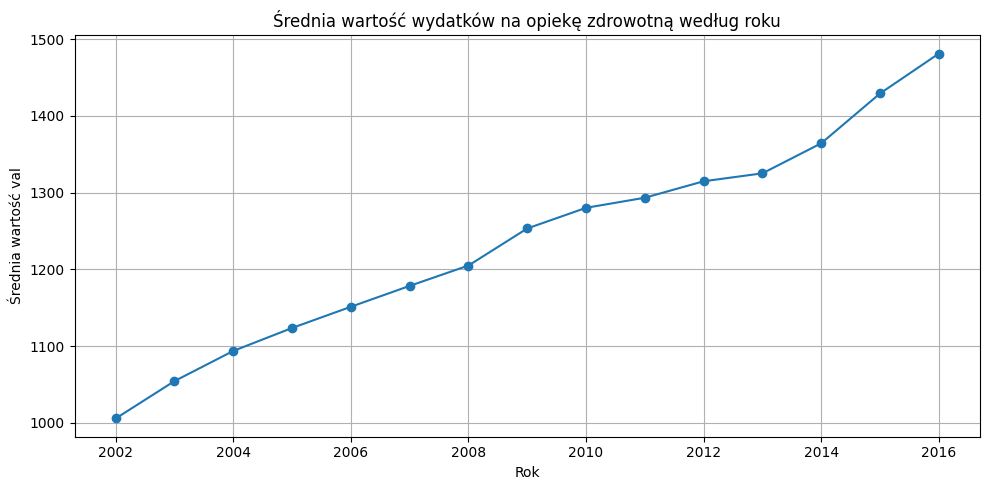

In [25]:
# Wykres średniej wartości wydatków według roku
plt.figure(figsize=(10, 5))
mean_by_year.plot(kind="line", marker="o")

plt.title("Średnia wartość wydatków na opiekę zdrowotną według roku")
plt.xlabel("Rok")
plt.ylabel("Średnia wartość val")
plt.grid(True)
plt.tight_layout()
plt.show()

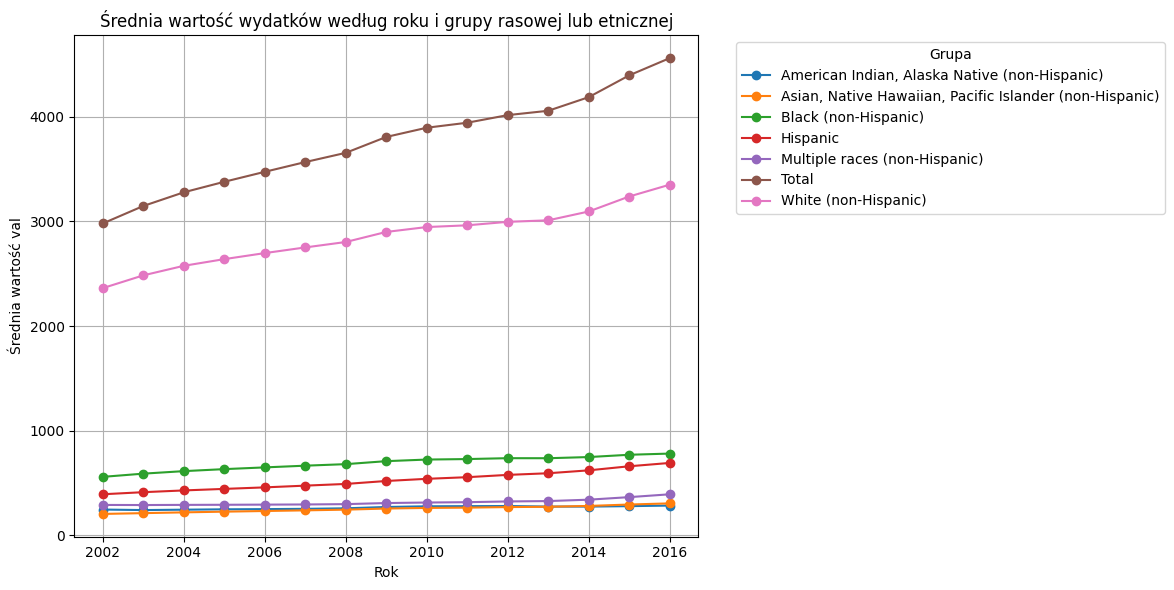

In [26]:
pivot.plot(figsize=(12, 6), marker="o")

plt.title("Średnia wartość wydatków według roku i grupy rasowej lub etnicznej")
plt.xlabel("Rok")
plt.ylabel("Średnia wartość val")
plt.legend(title="Grupa", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True)
plt.tight_layout()
plt.show()

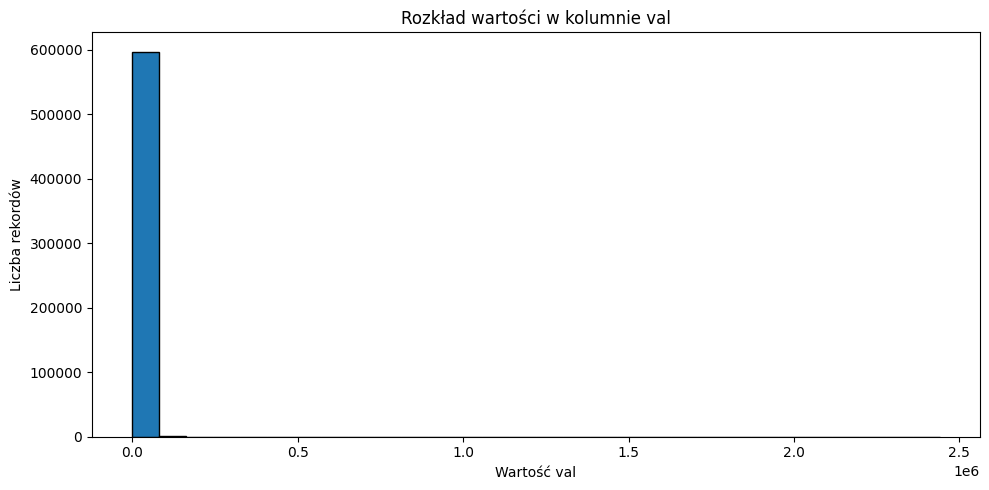

In [27]:
plt.figure(figsize=(10, 5))
df["val"].dropna().plot(kind="hist", bins=30, edgecolor="black")

plt.title("Rozkład wartości w kolumnie val")
plt.xlabel("Wartość val")
plt.ylabel("Liczba rekordów")
plt.tight_layout()
plt.show()

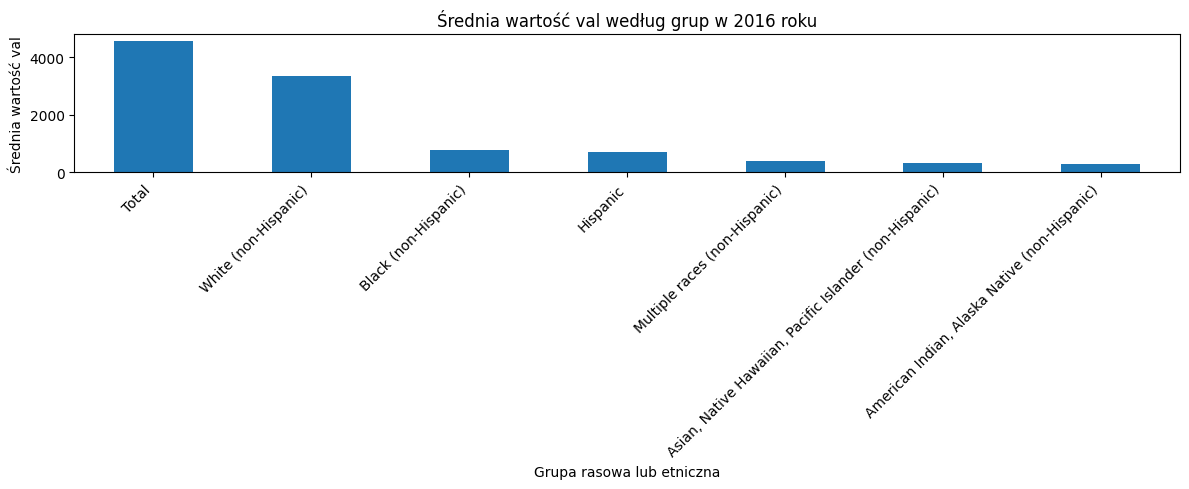

In [28]:
mean_by_race_2016 = (
    df[df["year"] == 2016]
    .groupby("race_ethnicity")["val"]
    .mean()
    .sort_values(ascending=False)
)

mean_by_race_2016.plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Średnia wartość val według grup w 2016 roku")
plt.xlabel("Grupa rasowa lub etniczna")
plt.ylabel("Średnia wartość val")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [29]:
# Przykładowe dane o grupach
df_groups = pd.DataFrame({
    "race_ethnicity": ["White", "Black", "Hispanic"],
    "group_code": [1, 2, 3]
})

df_values = pd.DataFrame({
    "race_ethnicity": ["White", "Black", "Hispanic"],
    "example_value": [100, 200, 300]
})

merged_df = pd.merge(
    df_groups,
    df_values,
    on="race_ethnicity",
    how="inner"
)

display(merged_df)

,race_ethnicity,group_code,example_value
0,White,1,100
1,Black,2,200
2,Hispanic,3,300


In [30]:
df_part1 = df[["year", "race_ethnicity", "val"]].head(5)
df_part2 = df[["year", "race_ethnicity", "val"]].tail(5)

combined_df = pd.concat(
    [df_part1, df_part2],
    ignore_index=True
)

display(combined_df)

,year,race_ethnicity,val
0,2002,"American Indian, Alaska Native (non-Hispanic)",104.39
1,2002,"American Indian, Alaska Native (non-Hispanic)",3.04
2,2002,"American Indian, Alaska Native (non-Hispanic)",24.87
3,2002,"American Indian, Alaska Native (non-Hispanic)",24.94
4,2002,"American Indian, Alaska Native (non-Hispanic)",2.02
5,2016,White (non-Hispanic),9.00
6,2016,White (non-Hispanic),6.00
7,2016,White (non-Hispanic),18.00
8,2016,White (non-Hispanic),31.00
9,2016,White (non-Hispanic),229.00


In [31]:
df_calculated = df[["year", "race_ethnicity", "val"]].copy()

df_calculated["val_times_1000"] = df_calculated["val"] * 1000

display(df_calculated.head(10))

,year,race_ethnicity,val,val_times_1000
0,2002,"American Indian, Alaska Native (non-Hispanic)",104.39,104390.0
1,2002,"American Indian, Alaska Native (non-Hispanic)",3.04,3040.0
2,2002,"American Indian, Alaska Native (non-Hispanic)",24.87,24870.0
3,2002,"American Indian, Alaska Native (non-Hispanic)",24.94,24940.0
4,2002,"American Indian, Alaska Native (non-Hispanic)",2.02,2020.0
5,2002,"American Indian, Alaska Native (non-Hispanic)",20.95,20950.0
6,2002,"American Indian, Alaska Native (non-Hispanic)",180.21,180210.0
7,2002,"American Indian, Alaska Native (non-Hispanic)",1.66,1660.0
8,2002,"American Indian, Alaska Native (non-Hispanic)",0.21,210.0
9,2002,"American Indian, Alaska Native (non-Hispanic)",1.59,1590.0


In [32]:
median_val = df["val"].median()

df_lambda = df[["year", "race_ethnicity", "val"]].copy()

df_lambda["category"] = df_lambda["val"].apply(
    lambda x: "wysoka wartość" if x > median_val else "niska wartość"
)

display(df_lambda.head(10))

,year,race_ethnicity,val,category
0,2002,"American Indian, Alaska Native (non-Hispanic)",104.39,wysoka wartość
1,2002,"American Indian, Alaska Native (non-Hispanic)",3.04,niska wartość
2,2002,"American Indian, Alaska Native (non-Hispanic)",24.87,niska wartość
3,2002,"American Indian, Alaska Native (non-Hispanic)",24.94,niska wartość
4,2002,"American Indian, Alaska Native (non-Hispanic)",2.02,niska wartość
5,2002,"American Indian, Alaska Native (non-Hispanic)",20.95,niska wartość
6,2002,"American Indian, Alaska Native (non-Hispanic)",180.21,wysoka wartość
7,2002,"American Indian, Alaska Native (non-Hispanic)",1.66,niska wartość
8,2002,"American Indian, Alaska Native (non-Hispanic)",0.21,niska wartość
9,2002,"American Indian, Alaska Native (non-Hispanic)",1.59,niska wartość


In [33]:
# Ponowne otwarcie archiwum ZIP
with zipfile.ZipFile(io.BytesIO(uploaded[zip_filename])) as z:
    csv_files = [name for name in z.namelist() if name.lower().endswith(".csv")]

    with z.open(csv_files[0]) as file:
        total_rows = 0

        for chunk in pd.read_csv(file, chunksize=100_000, low_memory=False):
            total_rows += len(chunk)

        print("Liczba rekordów odczytanych partiami:", total_rows)

Liczba rekordów odczytanych partiami: 598500


In [34]:
from google.colab import files

df.to_csv("healthcare_spending_export.csv", index=False)
files.download("healthcare_spending_export.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:
# Grupowanie po roku i grupie rasowej
multi_group = df.groupby(
    ["year", "race_ethnicity"]
)["val"].mean()

print("Nazwy poziomów indeksu:")
print(multi_group.index.names)

print("\nIndeks posortowany:")
display(multi_group.sort_index())

Nazwy poziomów indeksu:
['year', 'race_ethnicity']

Indeks posortowany:


year  race_ethnicity                                         
2002  American Indian, Alaska Native (non-Hispanic)               247.272467
      Asian, Native Hawaiian, Pacific Islander (non-Hispanic)     205.501889
      Black (non-Hispanic)                                        559.617925
      Hispanic                                                    393.325851
      Multiple races (non-Hispanic)                               291.439346
                                                                    ...     
2016  Black (non-Hispanic)                                        782.043353
      Hispanic                                                    692.492937
      Multiple races (non-Hispanic)                               393.035814
      Total                                                      4559.435056
      White (non-Hispanic)                                       3350.492663
Name: val, Length: 105, dtype: float64

In [36]:
print("Indeks tabeli przestawnej:")
print(pivot.index)

print("\nKolumny tabeli przestawnej:")
print(pivot.columns)

print("\nIndeks złożony tabeli przestawnej:")
pivot_multi = pivot.stack()
display(pivot_multi)

Indeks tabeli przestawnej:
Index([2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013,
       2014, 2015, 2016],
      dtype='int64', name='year')

Kolumny tabeli przestawnej:
Index(['American Indian, Alaska Native (non-Hispanic)',
       'Asian, Native Hawaiian, Pacific Islander (non-Hispanic)',
       'Black (non-Hispanic)', 'Hispanic', 'Multiple races (non-Hispanic)',
       'Total', 'White (non-Hispanic)'],
      dtype='object', name='race_ethnicity')

Indeks złożony tabeli przestawnej:


year  race_ethnicity                                         
2002  American Indian, Alaska Native (non-Hispanic)               247.272467
      Asian, Native Hawaiian, Pacific Islander (non-Hispanic)     205.501889
      Black (non-Hispanic)                                        559.617925
      Hispanic                                                    393.325851
      Multiple races (non-Hispanic)                               291.439346
                                                                    ...     
2016  Black (non-Hispanic)                                        782.043353
      Hispanic                                                    692.492937
      Multiple races (non-Hispanic)                               393.035814
      Total                                                      4559.435056
      White (non-Hispanic)                                       3350.492663
Length: 105, dtype: float64